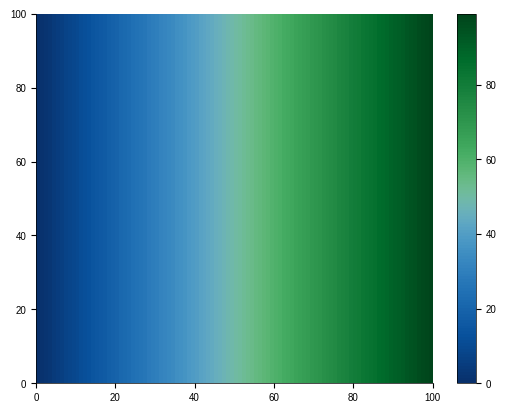

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap
import seaborn as sns
import json
import numpy as np
import dill
from typing import *
import torch
import random
import pandas as pd
import os

save_plots = True

if save_plots:
    dir_path = "plots/figure_4/"
    os.makedirs(dir_path, exist_ok=True)

top = colormaps['Blues_r'].resampled(128)
bottom = colormaps['Greens'].resampled(128)


w = np.linspace(-12, 12, 256)[:,None]
sigmoid = lambda x: 1/(1+np.exp(-x))
w = sigmoid(w)

newcolors = (1-w) * top(np.linspace(0.0, 1, 256)) + w * bottom(np.linspace(0.0, 1, 256))
newcmp = ListedColormap(newcolors, name='OrangeBlue')
psm = plt.pcolormesh(np.arange(100)[None,:].repeat(100, axis=0), cmap=newcmp)
plt.colorbar(psm)

np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

/tmp/ipykernel_21339/853158297.py:181: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(
/tmp/ipykernel_21339/853158297.py:343: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)
/tmp/ipykernel_21339/853158297.py:343: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


Text(0, 200, 'Contrastive')

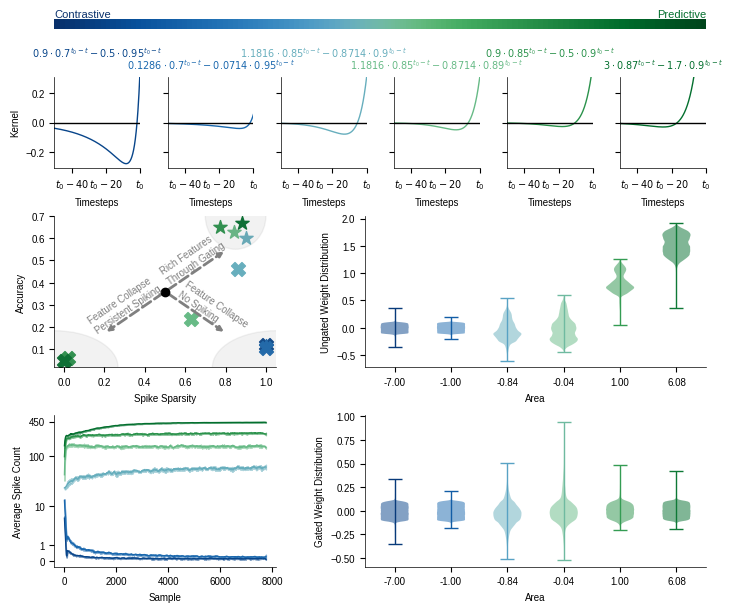

In [ ]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "Arial", "Helvetica"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.5,
    "lines.linewidth": 1.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False
})

mm = 1/25.4
width_sc = 180 * mm
height_sc = 150 * mm

fig = plt.figure(figsize=(width_sc, height_sc))
# fig = plt.figure(figsize=(20/1.5, 10))

gs = fig.add_gridspec(4, 6, height_ratios=[1, 9, 15, 15])
ax_color = fig.add_subplot(gs[0, :])
ax_trace0 = fig.add_subplot(gs[1, 0])
ax_trace1 = fig.add_subplot(gs[1, 1])
ax_trace2 = fig.add_subplot(gs[1, 2])
ax_trace3 = fig.add_subplot(gs[1, 3])
ax_trace4 = fig.add_subplot(gs[1, 4])
ax_trace5 = fig.add_subplot(gs[1, 5])

gs_bottom0 = gs[2, :].subgridspec(1, 2, width_ratios=[1.3, 2])
gs_bottom1 = gs[3, :].subgridspec(1, 2, width_ratios=[1.3, 2])
ax_scatter = fig.add_subplot(gs_bottom0[:, 0])
ax_early_spikes = fig.add_subplot(gs_bottom1[:, 0])

ax_violin_ug = fig.add_subplot(gs_bottom0[:, 1])
ax_violin_g = fig.add_subplot(gs_bottom1[:, 1])

# plt.tight_layout(pad=0.4, w_pad=1.8, h_pad=0.5)

axes = [ax_trace0, ax_trace1, ax_trace2, ax_trace3, ax_trace4, ax_trace5]

steps = 10
x_max = 50
x = np.linspace(0, x_max, steps * x_max)[::-1] 

title_font = {"size": 7}
lw = 1

# colors = [0, 33, 66, 180, 200, 220]
colors = [20, 55, 116, 140, 185, 220]
colors_second = list(map(lambda x: newcolors[x-10][:3], colors)) 
colors = list(map(lambda x: newcolors[x][:3], colors))


y = (-0.5000 * 0.95 ** x) + (0.9000 * 0.70 ** x) # -7
axes[0].plot(x[::-1], y, c=colors[0], linewidth=lw)
axes[0].set_title("$0.9 \cdot 0.7^{t_0-t} - 0.5 \cdot 0.95^{t_0 - t}$\n", color=colors[0], fontdict=title_font)

y = (-0.0714 * 0.95 ** x) + (0.1286 * 0.70 ** x) # -1
axes[1].plot(x[::-1], y, c=colors[1], linewidth=lw)
axes[1].set_title("\n$0.1286 \cdot 0.7^{t_0-t} - 0.0714 \cdot 0.95^{t_0 - t}$", color=colors[1], fontdict=title_font)
axes[1].set_yticklabels([])


y = (-0.8714 * 0.90 ** x) + (1.1816 * 0.85 ** x) # -0.83
axes[2].plot(x[::-1], y, c=colors[2], linewidth=lw)
axes[2].set_title("$1.1816 \cdot 0.85^{t_0-t} - 0.8714 \cdot 0.9^{t_0 - t}$\n", color=colors[2], fontdict=title_font)
axes[2].set_yticklabels([])

y = (-0.8714 * 0.89 ** x) + (1.1816 * 0.85 ** x) # -0.04
axes[3].plot(x[::-1], y, c=colors[3], linewidth=lw)
axes[3].set_title("\n$1.1816 \cdot 0.85^{t_0-t} - 0.8714 \cdot 0.89^{t_0 - t}$", color=colors[3], fontdict=title_font)
axes[3].set_yticklabels([])

y = (-0.5000 * 0.90 ** x) + (0.9000 * 0.85 ** x) # 1
axes[4].plot(x[::-1], y, c=colors[4], linewidth=lw)
axes[4].set_title("$0.9 \cdot 0.85^{t_0-t} - 0.5 \cdot 0.9^{t_0 - t}$\n", color=colors[4], fontdict=title_font)
axes[4].set_yticklabels([])

y = (-1.7000 * 0.90 ** x) + (3.0000 * 0.87 ** x) # 6
axes[5].plot(x[::-1], y, c=colors[5], linewidth=lw)
axes[5].set_title("\n$3 \cdot 0.87^{t_0-t} - 1.7 \cdot 0.9^{t_0 - t}$", color=colors[5], fontdict=title_font)
axes[5].set_yticklabels([])

# ax.legend(loc=2, prop={'size': 10})
for i, ax in enumerate(axes):
    # ax.set_xticklabels(labels)
    if i == 0:
        ax.set_ylabel("Kernel")
    ax.set_xlabel("Timesteps")
    ax.set_xlim(0, x_max)
    ax.set_ylim(-0.31, 0.31)
    # ax.set_xticks(np.arange(x_max+10, step=10))
    ax.set_xticks([10, 30, 50])
    # ax.grid()
    ax.plot(np.zeros_like(x), color="black")

labels = [item.get_text() for item in axes[0].get_xticklabels()]
for i in range(len(labels)):
    label = int(labels[i])
    label = label - x_max
    # idx = (i-len(labels)+1)*10
    if label == 0:
        labels[i] = "$t_0$"    
    else:
        labels[i] = "$t_0" + str(label) + "$"

for ax in axes:
    ax.set_xticklabels(labels)



ax_color.pcolormesh(np.arange(1000)[None,:].repeat(100, axis=0), cmap=newcmp)
ax_color.set_axis_off()

center_area = 0
center_acc = 0
center_acc_ung = 1
center_us = 0
center_ss = 0
center_ss_ung = 1
size = 100

# calc_entropy = lambda spike_sparsity: -spike_sparsity * np.log(spike_sparsity) - (1-spike_sparsity) * np.log(1-spike_sparsity)
# ax_scatter.grid()

layer = "layer_1"
metric = "test_metrics"

# offset = 0.25
# value = file["discrete area"] + 10
# file = json.load(open(path + "info.json", mode="rb"))
# 000000000000000000000000000000000000000
def plot_scatter(ax: plt.Axes, path: str, idx:int, gated:bool) -> None:
    marker = "X" if "ungated" in path else "*"
    
    spikes_mean_list = []
    acc_list = []
    runs = glob(path + "/*/final_checkpoint.pkl")
    for run in runs:
        chkp = dill.load(open(run , "rb"))
        spikes_mean = chkp[layer][metric]["spike_mean"]._values[-1]
        # spikes_mean = spikes_mean.cpu().numpy()
        spikes_mean_list.append(spikes_mean)

        val_accs = chkp["classifying1"]["val_loss"].cpu().numpy()
        best_idx = np.argmin(val_accs)
        test_acc = chkp["classifying1"]["test_acc"][best_idx]
        test_acc = test_acc.cpu().numpy()
        acc_list.append(test_acc)

        # print("best idx:", best_idx)
        # print("test_acc:", test_acc)

    spikes_mean = np.stack(spikes_mean_list, axis=0)
    spike_sparsity = 1 - spikes_mean
    test_acc = np.stack(acc_list, axis=0)

    if save_plots:
        data = {
            "spike_sparsity": spike_sparsity,
            "test_acc": test_acc,
        }
        name = "scatter_"
        if gated:
            name += "gated"
        else:
            name += "ungated"
        name += f"_{idx+1}"
        df = pd.DataFrame(data)
        df.to_csv(dir_path + name + ".csv")
    
    spike_sparsity = spike_sparsity.mean(axis=0)
    test_acc = test_acc.mean(axis=0)
    
    ax.scatter(
        x=spike_sparsity,
        y=test_acc,
        c=colors[idx],
        marker=marker,
        s=size,
    )

das = []
import matplotlib as mpl
def plot_violin(ax:plt.Axes, path:str, idx:int, add_tick:bool, gated:bool) -> dict:
    path += "/1/"
    if add_tick:
        file = json.load(open(path + "info.json", mode="rb"))
        da = file["discrete area"]
        das.append(f"{da:.2f}")

    checkpoint: dict[str, dict[str, Any]] = dill.load(open(path + "final_checkpoint.pkl", "rb"))
    weights = checkpoint[f"layer_1"]["state_dict"]["layer.ff.weight"]
    weights = weights.detach().cpu().numpy()
    weights = weights.reshape(-1)

    if save_plots:
        data = {
            "weights": weights,
        }
        name = "weights_"
        if gated:
            name += "gated"
        else:
            name += "ungated"
        name += f"{idx+1}"
        df = pd.DataFrame(data)
        df.to_csv(dir_path + name + ".csv")

    violin_parts = ax.violinplot(
        dataset=weights, 
        positions=[idx],
        # color=color[idx]
    )

    for partname in ('cbars','cmins','cmaxes','cmeans','cmedians'):
        if partname in violin_parts.keys():
            violin_parts[partname].set_edgecolor(colors_second[idx])
    
    for i, vp in enumerate(violin_parts['bodies']):
        vp.set_facecolor(colors[idx])
        # vp.set_edgecolor(colors_second[idx])
        # vp.set_linewidth(1)
        vp.set_alpha(0.5)
    return violin_parts


from glob import glob
from scipy.signal import savgol_filter


def plot_early_spikes(ax: plt.Axes, path: str, idx:int) -> None:
    spikes_list = []
    runs = glob(path + "/*/final_checkpoint.pkl")
    for run in runs:
        chkp = dill.load(open(run , "rb"))
        x = chkp["layer_1"]["spikes"][:,0,:].cpu().numpy()
        
        x_reshaped = []
        for i in range(0, x.shape[0], 100):
            x_reshaped.append(x[i:i+100, ...])
        x_reshaped = np.stack(x_reshaped, axis=1) # (T, B, N)

        spikes_list.append(x_reshaped)

    spikes = np.stack(spikes_list, axis=0) # (R, T, B, N)

    max_spikes = spikes.sum(axis=3).mean(axis=1) # (R, B)
    if save_plots:
        data = {f"run{i}": max_spikes[i,...] for i in range(max_spikes.shape[0])}
        name = f"max_spikes_{idx+1}"
        df = pd.DataFrame(data)
        df.to_csv(dir_path + name + ".csv")
    
    # Smooth each seed individually to reveal underlying trend
    max_spikes_smooth = savgol_filter(max_spikes, window_length=201, polyorder=3, axis=1)

    # Log transform (add 1 to handle zeros)
    max_spikes_log = np.log10(max_spikes_smooth + 1.0)

    # Mean and SD across runs in log space
    mean_log = max_spikes_log.mean(axis=0)
    std_log = max_spikes_log.std(axis=0)

    B = mean_log.shape[0]

    # Plot mean curve
    ax.plot(np.arange(1, B+1), mean_log, color=colors[idx], linewidth=1.0)

    # Plot unsmoothed SD band in log space
    ax.fill_between(np.arange(1, B+1), mean_log - std_log, mean_log + std_log, alpha=0.5, color=colors[idx])


path = "results/tdcl_full_online/shd/ff/ablation_2layer_450/B1_bins100rotate5_beta0.5_(-0.5000_0.95)_(0.9000_0.70)_carry_warmp_up20_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=0, gated=True)
plot_violin(ax_violin_g, path, idx=0, add_tick=True, gated=True)
path = "results/tdcl_full_online/shd/ff/ablation_1layer_450_ungated_for_real/B1_bins100rotate5_beta0.5_(-0.5000_0.95)_(0.9000_0.70)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=0, gated=False)
plot_violin(ax_violin_ug, path, idx=0, add_tick=False, gated=False)
path = "results/tdcl_full_online/shd/ff/1_layer_450neurons_early_training_one_epoch/B1_bins100rotate5_beta0.5_(-0.5000_0.95)_(0.9000_0.70)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs100/"
plot_early_spikes(ax_early_spikes, path, idx=0)

# 111111111111111111111111111111111111111
path = "results/tdcl_full_online/shd/ff/ablation_2layer_450/B1_bins100rotate5_beta0.5_(-0.0714_0.95)_(0.1286_0.70)_carry_warmp_up20_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=1, gated=True)
plot_violin(ax_violin_g, path, idx=1, add_tick=True, gated=True)
path = "results/tdcl_full_online/shd/ff/ablation_1layer_450_ungated_for_real/B1_bins100rotate5_beta0.5_(-0.0714_0.95)_(0.1286_0.70)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=1, gated=False)
plot_violin(ax_violin_ug, path, idx=1, add_tick=False, gated=False)
path = "results/tdcl_full_online/shd/ff/1_layer_450neurons_early_training_one_epoch/B1_bins100rotate5_beta0.5_(-0.0714_0.95)_(0.1286_0.70)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs100/"
plot_early_spikes(ax_early_spikes, path, idx=1)

# 222222222222222222222222222222222222222
path = "results/tdcl_full_online/shd/ff/ablation_2layer_450/B1_bins100rotate5_beta0.5_(-0.8714_0.90)_(1.1816_0.85)_carry_warmp_up20_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=2, gated=True)
plot_violin(ax_violin_g, path, idx=2, add_tick=True, gated=True)
path = "results/tdcl_full_online/shd/ff/ablation_1layer_450_ungated_for_real/B1_bins100rotate5_beta0.5_(-0.8714_0.90)_(1.1816_0.85)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=2, gated=False)
plot_violin(ax_violin_ug, path, idx=2, add_tick=False, gated=False)
path = "results/tdcl_full_online/shd/ff/1_layer_450neurons_early_training_one_epoch/B1_bins100rotate5_beta0.5_(-0.8714_0.90)_(1.1816_0.85)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs100/"
plot_early_spikes(ax_early_spikes, path, idx=2)

# 333333333333333333333333333333333333333
path = "results/tdcl_full_online/shd/ff/ablation_2layer_450/B1_bins100rotate5_beta0.5_(-0.8714_0.89)_(1.1816_0.85)_carry_warmp_up20_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=3, gated=True)
plot_violin(ax_violin_g, path, idx=3, add_tick=True, gated=True)
path = "results/tdcl_full_online/shd/ff/ablation_1layer_450_ungated_for_real/B1_bins100rotate5_beta0.5_(-0.8714_0.89)_(1.1816_0.85)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=3, gated=False)
plot_violin(ax_violin_ug, path, idx=3, add_tick=False, gated=False)
path = "results/tdcl_full_online/shd/ff/1_layer_450neurons_early_training_one_epoch/B1_bins100rotate5_beta0.5_(-0.8714_0.89)_(1.1816_0.85)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs100/"
plot_early_spikes(ax_early_spikes, path, idx=3)

# 444444444444444444444444444444444444444
path = "results/tdcl_full_online/shd/ff/ablation_2layer_450/B1_bins100rotate5_beta0.5_(-0.5000_0.90)_(0.9000_0.85)_carry_warmp_up20_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=4 ,gated=True)
plot_violin(ax_violin_g, path, idx=4, add_tick=True, gated=True)
path = "results/tdcl_full_online/shd/ff/ablation_1layer_450_ungated_for_real/B1_bins100rotate5_beta0.5_(-0.5000_0.90)_(0.9000_0.85)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=4, gated=False)
plot_violin(ax_violin_ug, path, idx=4, add_tick=False, gated=False)
path = "results/tdcl_full_online/shd/ff/1_layer_450neurons_early_training_one_epoch/B1_bins100rotate5_beta0.5_(-0.5000_0.90)_(0.9000_0.85)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs100/"
plot_early_spikes(ax_early_spikes, path, idx=4)

# 555555555555555555555555555555555555555
path = "results/tdcl_full_online/shd/ff/ablation_2layer_450/B1_bins100rotate5_beta0.5_(-1.7000_0.90)_(3.0000_0.87)_carry_warmp_up20_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=5, gated=True)
plot_violin(ax_violin_g, path, idx=5, add_tick=True, gated=True)
path = "results/tdcl_full_online/shd/ff/ablation_1layer_450_ungated_for_real/B1_bins100rotate5_beta0.5_(-1.7000_0.90)_(3.0000_0.87)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs10/"
plot_scatter(ax_scatter, path, idx=5, gated=False)
plot_violin(ax_violin_ug, path, idx=5, add_tick=False, gated=False)
path = "results/tdcl_full_online/shd/ff/1_layer_450neurons_early_training_one_epoch/B1_bins100rotate5_beta0.5_(-1.7000_0.90)_(3.0000_0.87)_carry_warmp_up20_inp_thr-inf_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs100/"
plot_early_spikes(ax_early_spikes, path, idx=5)

def set_violin_axis(ax:plt.Axes) -> None:
    labels = [item.get_text() for item in ax.get_xticklabels()]
    labels = [labels[0]] + das
    
    ax.set_xticklabels(labels)
    ax.set_xlabel("Area")

set_violin_axis(ax_violin_g)
ax_violin_g.set_ylabel("Gated Weight Distribution")

set_violin_axis(ax_violin_ug)
ax_violin_ug.set_ylabel("Ungated Weight Distribution")

# ax_violin_g.set_title("Gated Weight Distribution")
# ax_violin_ug.set_title("Ungated Weight Distribution")

x_lim, y_lim = ax_scatter.get_xlim(), ax_scatter.get_ylim() 

from matplotlib.patches import Ellipse
# circle1 = plt.Circle((0.2, 0), 0.2, color='gray', alpha=0.2, edgecolor='red')
width = 0.63
height = 0.33
color = "gray"
alpha = 0.1
ellipse1 = Ellipse((x_lim[0], y_lim[0]), width=width, height=height, color=color, alpha=alpha)
ax_scatter.add_patch(ellipse1)
ellipse2 = Ellipse((x_lim[1], y_lim[0]), width=width, height=height, color=color, alpha=alpha)
ax_scatter.add_patch(ellipse2)
ellipse3 = Ellipse((x_lim[1]-0.2, y_lim[1]), width=0.3, height=0.3, color=color, alpha=alpha)
ax_scatter.add_patch(ellipse3)


ax_scatter.set_xlim(x_lim)
ax_scatter.set_ylim(y_lim)

center_x = (x_lim[0] + x_lim[1]) / 2
center_y = (y_lim[0] + y_lim[1]) / 2
center = np.array((center_x, center_y))
ax_scatter.scatter(*center, color="black", zorder=2)


arrowprops = {
    "arrowstyle": "-|>",
    "lw": 2,
    "ls": "--",
    "color": "gray"
}

length = 550
diff_line1 = center - np.array((x_lim[0], y_lim[0]))
line_arrow1 = center[:,None] - diff_line1[:,None] * np.linspace(0, 1, 1000)[None, :]
ax_scatter.annotate("", xytext=center, xy=line_arrow1[:,length], arrowprops=arrowprops, zorder=1)

diff_line2 = center - np.array((x_lim[1], y_lim[1]))
line_arrow2 = center[:,None] - diff_line2[:,None] * np.linspace(0, 1, 1000)[None, :]
ax_scatter.annotate("", xytext=center, xy=line_arrow2[:,length], arrowprops=arrowprops, zorder=1)

diff_line3 = center - np.array((x_lim[1], y_lim[0]))
line_arrow3 = center[:,None] - diff_line3[:,None] * np.linspace(0, 1, 1000)[None, :]
ax_scatter.annotate("", xytext=center, xy=line_arrow3[:,length], arrowprops=arrowprops, zorder=1)

def calc_angle(arrow:np.ndarray) -> np.ndarray:
    dx = arrow[0, 0] - arrow[0, -1]
    dy = arrow[1, 0] - arrow[1, -1]
    angle = np.arctan2(dy, dx)
    angle = np.rad2deg(angle)
    return angle

fontdict = {
    "size": 7,
    "color": "gray"
}

angle1 = calc_angle(line_arrow1)
text_anchor = line_arrow1[:,600] + np.array([0, 0.01])
ax_scatter.text(*text_anchor, 'Feature Collapse\nPersistent Spiking', ha='left', va='bottom',
         transform_rotates_text=True, rotation=angle1, rotation_mode='anchor', fontdict=fontdict)


text_anchor = line_arrow2[:,50] + np.array([0, 0.01])
ax_scatter.text(*text_anchor, 'Rich Features\nThrough Gating', ha='left', va='bottom',
         transform_rotates_text=True, rotation=angle1, rotation_mode='anchor', fontdict=fontdict)

angle3 = calc_angle(line_arrow3) + 180
text_anchor = line_arrow3[:,100] + np.array([0, 0.01])
ax_scatter.text(*text_anchor, 'Feature Collapse\nNo Spiking', ha='left', va='bottom',
         transform_rotates_text=True, rotation=angle3, rotation_mode='anchor', fontdict=fontdict)


ax_scatter.set_xlabel("Spike Sparsity")
ax_scatter.set_ylabel("Accuracy")

def plot_scatter(ax: plt.Axes, path: str, idx:int) -> None:
    marker = "X" if "ungated" in path else "*"
    checkpoint: dict[str, dict[str, Any]] = dill.load(open(path + "final_checkpoint.pkl", "rb"))
    ax.scatter(
        x=1-checkpoint[layer][metric]["spike_mean"]._values[-1],
        y=max(checkpoint["few_shot"]["test_acc"]),
        c=colors[idx],
        marker=marker,
        s=size,
    )


ax_early_spikes.set_xlabel("Sample")
ax_early_spikes.set_ylabel("Average Spike Count")
raw_ticks = [0, 1, 10, 100, 450]
log_ticks = [np.log10(v + 1) for v in raw_ticks]
ax_early_spikes.set_yticks(log_ticks)
ax_early_spikes.set_yticklabels([str(v) for v in raw_ticks])


plt.tight_layout(pad=0.4, w_pad=1.8, h_pad=0.5)
ax_color.text(1000, 200, s="Predictive", ha="right", va="top", fontdict={"size": 8}, color=newcolors[220])
ax_color.text(0, 200, s="Contrastive", ha="left", va="top", fontdict={"size": 8}, color=newcolors[0])

In [17]:
if save_plots:
    fig.savefig(dir_path + "/figure_4.svg", bbox_inches="tight")